# Evaluation & Finalization
Rules: test set evaluated exactly once, after the justification doc exists.
Task 0 verifies artifact provenance; Task 1 verifies the sealed split and
pipeline contract. No test predictions are made in this notebook section.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, joblib

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.models.utils.augmentation import stratified_mixup

df = pd.read_csv(PROJECT_ROOT / "data/processed/merged_rice_yield_dataset.csv")
df["temp_mean_c"] = (df["temp_max_c"] + df["temp_min_c"]) / 2
df["temp_range_c"] = df["temp_max_c"] - df["temp_min_c"]

split = json.load(open(PROJECT_ROOT / "artifacts/split_provinces.json"))
df_tr = df[df["province"].isin(split["train_provinces"])].copy()

FEATS = ["season_period", "ecosystem", "island_group", "area_harvested_ha",
         "n_application_rate", "p_application_rate", "k_application_rate",
         "total_fertilizer_kg_ha", "fertilizer_diversification_index",
         "rainfall_mm", "solar_radiation_mj_m2", "soil_ph",
         "temp_mean_c", "temp_range_c"]
X_raw = df_tr[FEATS]
y = df_tr["yield_mt_ha"].to_numpy()
strata = (df_tr["season_period"] + "|" + df_tr["ecosystem"] + "|"
          + df_tr["island_group"]).to_numpy()

pipe = joblib.load(PROJECT_ROOT / "models/preprocessing_pipeline.joblib")
X_proc = pipe.transform(X_raw)
if hasattr(X_proc, "toarray"):
    X_proc = X_proc.toarray()

# Deterministic reconstruction of the final training matrix (mixup 3x, seed 42)
Xf, yf, wf = stratified_mixup(X_proc, y, strata, multiplier=3, random_state=42)

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
refit = {
    "ridge": Ridge(alpha=1.0, random_state=42),
    "random_forest": RandomForestRegressor(
        n_estimators=500, min_samples_leaf=2, random_state=42, n_jobs=1),
}
for name, m in refit.items():
    m.fit(Xf, yf, sample_weight=wf)
    saved = joblib.load(PROJECT_ROOT / f"models/model_{name}.joblib")
    d = np.abs(m.predict(Xf) - saved.predict(Xf)).max()
    verdict = "MATCH: saved model is the mixup-3x model" if d < 1e-8 \
              else "MISMATCH: saved model was NOT trained on mixup-3x data!"
    print(f"{name}: max |refit - saved| prediction diff = {d:.2e} -> {verdict}")

ridge: max |refit - saved| prediction diff = 0.00e+00 -> MATCH: saved model is the mixup-3x model
random_forest: max |refit - saved| prediction diff = 2.66e-15 -> MATCH: saved model is the mixup-3x model


In [2]:
df_te = df[df["province"].isin(split["test_provinces"])].copy()
y_te = df_te["yield_mt_ha"].to_numpy()   # stored, NOT used until Task 3

print("test rows:", len(df_te), "| test provinces:", df_te["province"].nunique())
print("counts match seed file:",
      len(df_te) == split["n_test_rows"], df_tr.shape[0] == split["n_train_rows"])
print("test provinces == split file list:",
      sorted(df_te["province"].unique()) == sorted(split["test_provinces"]))
print("province overlap train vs test:",
      len(set(df_te["province"]) & set(df_tr["province"])))

X_te = pipe.transform(df_te[FEATS])
if hasattr(X_te, "toarray"):
    X_te = X_te.toarray()
fo = json.load(open(PROJECT_ROOT / "artifacts/feature_order.json"))
print("test processed shape:", X_te.shape)
print("pipeline output names == feature_order.json:",
      list(pipe.get_feature_names_out()) == fo)

test rows: 58 | test provinces: 16
counts match seed file: True True
test provinces == split file list: True
province overlap train vs test: 0
test processed shape: (58, 15)
pipeline output names == feature_order.json: True


--- OFFICIAL TEST SET METRICS (Ridge + Mixup 3x) ---
Test RMSE: 0.7022
Test MAE:  0.4747
Test R²:   0.2818


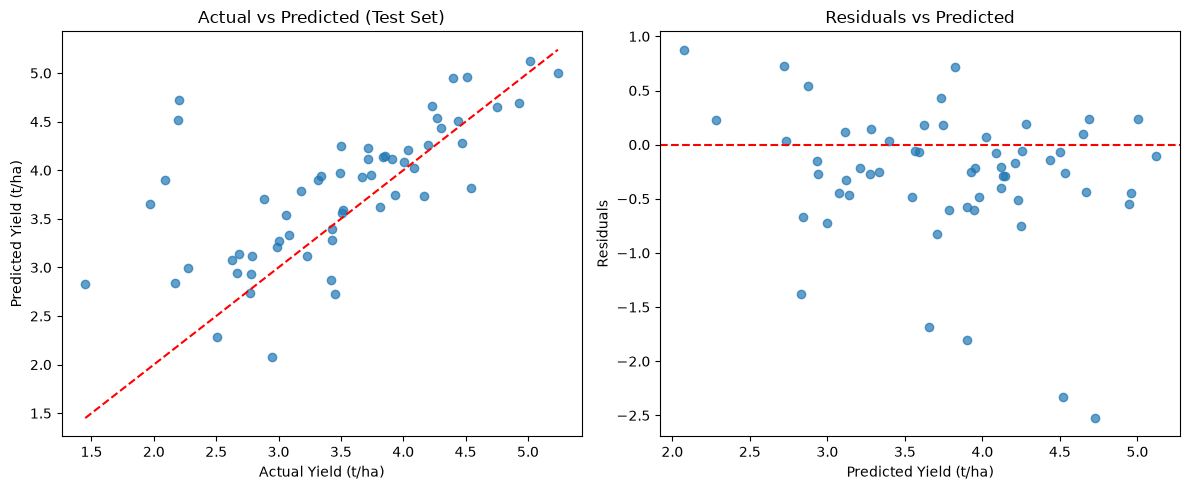

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load the selected model
ridge_model = joblib.load(PROJECT_ROOT / "models/model_ridge.joblib")

# 2. ONE-TIME prediction on the sealed test set (X_te is already processed)
y_pred = ridge_model.predict(X_te)

# 3. Calculate official test metrics
test_rmse = np.sqrt(mean_squared_error(y_te, y_pred))
test_mae = mean_absolute_error(y_te, y_pred)
test_r2 = r2_score(y_te, y_pred)

print("--- OFFICIAL TEST SET METRICS (Ridge + Mixup 3x) ---")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test MAE:  {test_mae:.4f}")
print(f"Test R²:   {test_r2:.4f}")

# 4. Residual Analysis Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_te, y_pred, alpha=0.7)
axes[0].plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'r--')
axes[0].set_xlabel("Actual Yield (t/ha)")
axes[0].set_ylabel("Predicted Yield (t/ha)")
axes[0].set_title("Actual vs Predicted (Test Set)")

# Plot 2: Residuals vs Predicted
residuals = y_te - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.7)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel("Predicted Yield (t/ha)")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs Predicted")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "docs/figures/test_set_residuals.png", dpi=300)
plt.show()

In [4]:
res_df = pd.DataFrame({
    "province": df_te["province"].to_numpy(),
    "ecosystem": df_te["ecosystem"].to_numpy(),
    "season_period": df_te["season_period"].to_numpy(),
    "actual": y_te,
    "predicted": y_pred,
})
res_df["residual"] = res_df["actual"] - res_df["predicted"]
res_df["abs_err"] = res_df["residual"].abs()

print("Worst 6 test rows by absolute error:")
print(res_df.sort_values("abs_err", ascending=False).head(6).round(2).to_string(index=False))

print("\nMean absolute error by ecosystem:")
print(res_df.groupby("ecosystem")["abs_err"].mean().round(3))

print("\nWorst 5 provinces by mean absolute error:")
print(res_df.groupby("province")["abs_err"].mean()
      .sort_values(ascending=False).head(5).round(3))

res_df.to_csv(PROJECT_ROOT / "artifacts/test_predictions.csv", index=False)
print("\nSaved: artifacts/test_predictions.csv")

Worst 6 test rows by absolute error:
         province     ecosystem   season_period  actual  predicted  residual  abs_err
  Dinagat Islands     Irrigated 2021_Semester_2    2.20       4.73     -2.53     2.53
  Dinagat Islands     Irrigated 2022_Semester_1    2.19       4.52     -2.33     2.33
  Dinagat Islands Non-irrigated 2021_Semester_2    2.09       3.90     -1.81     1.81
  Dinagat Islands Non-irrigated 2022_Semester_1    1.97       3.66     -1.69     1.69
Negros Occidental Non-irrigated 2022_Semester_1    1.45       2.83     -1.38     1.38
   Northern Samar Non-irrigated 2021_Semester_2    2.95       2.07      0.88     0.88

Mean absolute error by ecosystem:
ecosystem
Irrigated        0.459
Non-irrigated    0.494
Name: abs_err, dtype: float64

Worst 5 provinces by mean absolute error:
province
Dinagat Islands      2.088
Negros Occidental    0.742
Northern Samar       0.525
Benguet              0.456
Sultan Kudarat       0.433
Name: abs_err, dtype: float64

Saved: artifacts/test_